# Linear Regression: Predicting Resistance from Temperature and Material

**Goal:** Build a model that predicts the **resistance (Ω)** of a wire using two inputs:
- **Temperature (°C)**
- **Type of material** (copper, aluminum, iron, tungsten)

**Physics behind the data:** `R = R20 × (1 + α × (T − 20))`, where `R20` is the resistance at 20 °C and `α` is the temperature coefficient of the material.

Run each cell from top to bottom (Shift + Enter).

## Step 1: Import libraries

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

np.random.seed(42)

## Step 2: Create the dataset
We simulate measurements of a wire (10 m long, 1 mm² cross-section) and add a little noise, like a real instrument would have.
In your own class you can replace this with real lab measurements.

In [43]:
# material: (resistance at 20 C in ohm, temperature coefficient alpha)
materials = {
    "copper":   (0.168, 0.0039),
    "aluminum": (0.282, 0.0043),
    "iron":     (0.971, 0.0065),
    "tungsten": (0.560, 0.0045),
}

rows = []
for name, (r20, alpha) in materials.items():
    for _ in range(50):
        T = np.random.uniform(0, 200)              # temperature in C
        R = r20 * (1 + alpha * (T - 20))           # true resistance
        R += np.random.normal(0, 0.01)             # measurement noise
        rows.append([name, T, R])

df = pd.DataFrame(rows, columns=["material", "temperature", "resistance"])
df.head()

,material,temperature,resistance
0,copper,74.908024,0.192857
1,copper,31.198904,0.178527
2,copper,11.616722,0.165298
3,copper,141.614516,0.257787
4,copper,4.116899,0.151785


## Step 3: Inputs (X) and output (y)
The model only understands numbers, so the text column `material` is converted into 0/1 columns. This is called **one-hot encoding**.

In [44]:
X = pd.get_dummies(df[["material", "temperature"]], columns=["material"], dtype=int)
y = df["resistance"]
X.head()

,temperature,material_aluminum,material_copper,material_iron,material_tungsten
0,74.908024,0,1,0,0
1,31.198904,0,1,0,0
2,11.616722,0,1,0,0
3,141.614516,0,1,0,0
4,4.116899,0,1,0,0


## Step 4: Split into training and testing data
The model learns from 80% of the data and is tested on the 20% it has never seen.

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 160
Testing samples : 40


## Step 5: Train the model

In [46]:
model = LinearRegression()
# model = logisticRegression()
model.fit(X_train, y_train)
print("Model trained!")

Model trained!


## Step 6: Evaluate the model

In [47]:
pred = model.predict(X_test)


print("\nWhat the model learned:")
print(f"  intercept           : {model.intercept_:.4f}")
for col, coef in zip(X.columns, model.coef_):
    print(f"  {col:20s}: {coef:.4f}")


What the model learned:
  intercept           : 0.4348
  temperature         : 0.0028
  material_aluminum   : -0.3007
  material_copper     : -0.4804
  material_iron       : 0.7438
  material_tungsten   : 0.0373


## Step 7: Predict a new case

In [48]:
def predict(material, temperature, mdl=model, cols=X.columns):
    row = {c: 0 for c in cols}
    row["temperature"] = temperature
    row["material_" + material] = 1
    return mdl.predict(pd.DataFrame([row]))[0]

print("Copper at 100 C ->", round(predict("copper", 100), 3), "ohm")
print("Iron   at 100 C ->", round(predict("iron", 100), 3), "ohm")

Copper at 100 C -> 0.239 ohm
Iron   at 100 C -> 1.463 ohm


## Step 8: Plot the result

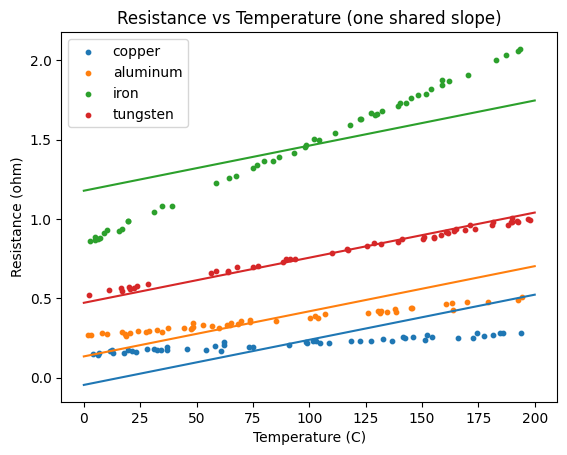

In [49]:
t = np.linspace(0, 200, 50)
for m in materials:
    sub = df[df.material == m]
    plt.scatter(sub.temperature, sub.resistance, s=10, label=m)
    plt.plot(t, [predict(m, v) for v in t])

plt.xlabel("Temperature (C)")
plt.ylabel("Resistance (ohm)")
plt.title("Resistance vs Temperature (one shared slope)")
plt.legend()
plt.show()

## Step 9: Why isn't the fit perfect?
Look at the plot: the lines are all **parallel**, because the model learned **one shared temperature slope** for every material.
In reality each material has its own slope (iron's resistance rises faster than copper's).

**Fix:** add **interaction features** (`temperature × material`), so each material can get its own slope.

Shared slope  R2: 0.9094 | MAE: 0.09
Per-material  R2: 0.9994 | MAE: 0.0082


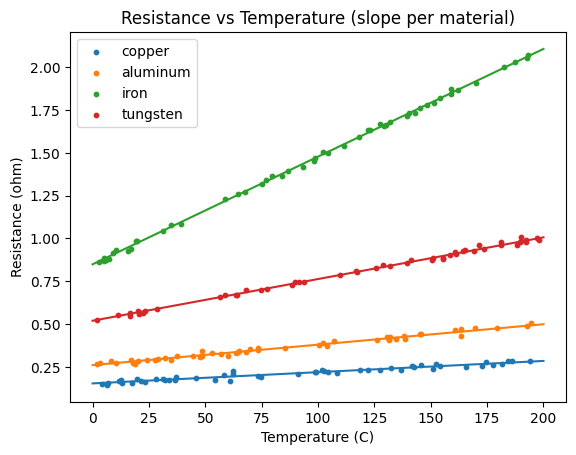

In [50]:
# Interaction features: each material gets its own slope
X2 = X.copy()
for m in materials:
    X2["material_" + m + "_x_temp"] = X2["material_" + m] * X2["temperature"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=1
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
pred2 = model2.predict(X2_test)

print("Shared slope  R2:", round(r2_score(y_test, pred), 4),
      "| MAE:", round(mean_absolute_error(y_test, pred), 4))
print("Per-material  R2:", round(r2_score(y2_test, pred2), 4),
      "| MAE:", round(mean_absolute_error(y2_test, pred2), 4))

# Prediction helper for model 2
def predict2(material, temperature):
    row = {c: 0 for c in X2.columns}
    row["temperature"] = temperature
    row["material_" + material] = 1
    row["material_" + material + "_x_temp"] = temperature
    return model2.predict(pd.DataFrame([row]))[0]

# Plot: one line per material
t = np.linspace(0, 200, 50)
plt.figure()
for m in materials:
    sub = df[df.material == m]
    plt.scatter(sub.temperature, sub.resistance, s=10, label=m)
    plt.plot(t, [predict2(m, v) for v in t])

plt.xlabel("Temperature (C)")
plt.ylabel("Resistance (ohm)")
plt.title("Resistance vs Temperature (slope per material)")
plt.legend()
plt.show()

## Exercises for students
1. Which material has the steepest line? Does that match its `α` value?
2. Add a new material (for example, nichrome: R20 = 11.0, α = 0.0004) and retrain.
3. Add wire **length** and **area** as new input features (`R = ρL/A`).
4. Change `test_size` to 0.5. What happens to the scores?
5. Replace the simulated data with real measurements from your lab.

Shared slope  R2: 0.9094 | MAE: 0.09
Per-material  R2: 0.9994 | MAE: 0.0082
Copper at 100 C -> 0.219 ohm
Iron   at 100 C -> 1.478 ohm


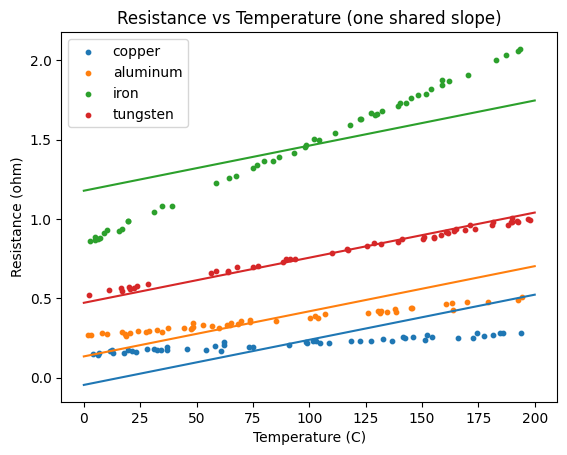

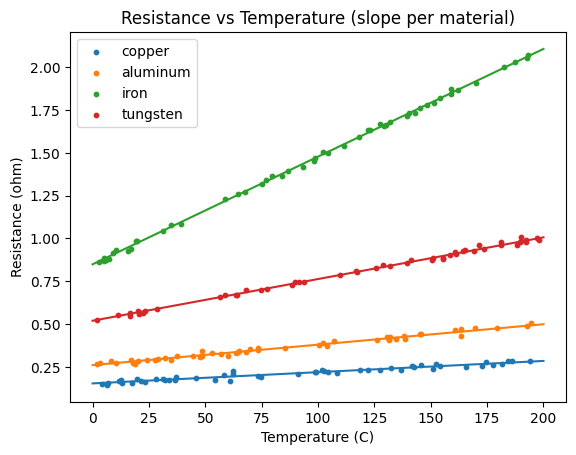

In [51]:
# The whole code for both models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

# ---------- 1. Generate data ----------
np.random.seed(42)
# material: (resistance at 20 C in ohm, temperature coefficient alpha)
materials = {
    "copper":   (0.168, 0.0039),
    "aluminum": (0.282, 0.0043),
    "iron":     (0.971, 0.0065),
    "tungsten": (0.560, 0.0045),
}

rows = []
for name, (r20, alpha) in materials.items():
    for _ in range(50):
        T = np.random.uniform(0, 200)
        R = r20 * (1 + alpha * (T - 20))
        R += np.random.normal(0, 0.01)
        rows.append([name, T, R])

df = pd.DataFrame(rows, columns=["material", "temperature", "resistance"])

# ---------- 2. Features and split ----------
X = pd.get_dummies(df[["material", "temperature"]], columns=["material"], dtype=int)
y = df["resistance"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# ---------- 3. Model 1: one shared slope ----------
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

def predict(material, temperature, mdl=model, cols=X.columns):
    row = {c: 0 for c in cols}
    row["temperature"] = temperature
    row["material_" + material] = 1
    return mdl.predict(pd.DataFrame([row]))[0]

# ---------- 4. Model 2: separate slope per material ----------
X2 = X.copy()
for m in materials:
    X2["material_" + m + "_x_temp"] = X2["material_" + m] * X2["temperature"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=1
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
pred2 = model2.predict(X2_test)

def predict2(material, temperature):
    row = {c: 0 for c in X2.columns}
    row["temperature"] = temperature
    row["material_" + material] = 1
    row["material_" + material + "_x_temp"] = temperature
    return model2.predict(pd.DataFrame([row]))[0]

# ---------- 5. Compare ----------
print("Shared slope  R2:", round(r2_score(y_test, pred), 4),
      "| MAE:", round(mean_absolute_error(y_test, pred), 4))
print("Per-material  R2:", round(r2_score(y2_test, pred2), 4),
      "| MAE:", round(mean_absolute_error(y2_test, pred2), 4))

print("Copper at 100 C ->", round(predict2("copper", 100), 3), "ohm")
print("Iron   at 100 C ->", round(predict2("iron", 100), 3), "ohm")

# ---------- 6. Plots ----------
t = np.linspace(0, 200, 50)

plt.figure()
for m in materials:
    sub = df[df.material == m]
    plt.scatter(sub.temperature, sub.resistance, s=10, label=m)
    plt.plot(t, [predict(m, v) for v in t])
plt.xlabel("Temperature (C)")
plt.ylabel("Resistance (ohm)")
plt.title("Resistance vs Temperature (one shared slope)")
plt.legend()
plt.show()

plt.figure()
for m in materials:
    sub = df[df.material == m]
    plt.scatter(sub.temperature, sub.resistance, s=10, label=m)
    plt.plot(t, [predict2(m, v) for v in t])
plt.xlabel("Temperature (C)")
plt.ylabel("Resistance (ohm)")
plt.title("Resistance vs Temperature (slope per material)")
plt.legend()
plt.show()